# Validation

1) Map Forecast, Impact

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os

import pandas as pd
import xarray as xr
from dotenv import find_dotenv, load_dotenv

from datetime import datetime, UTC

from utils import analysis_utils, isku_utils, plotting_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.isku_utils' from '/home/emily_zuetell/projects/poreallas/utils/isku_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

# Define Forecast
EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]

In [3]:
RUN_MONTH = "2026-10"
N_LEADS = 6

_months = pd.period_range(pd.Period(RUN_MONTH, "M"), periods=N_LEADS, freq="M")
FC_MONTHS = [p.month for p in _months]
FC_PERIOD = slice(
    _months[0].start_time.strftime("%Y-%m-%d"),
    _months[-1].end_time.strftime("%Y-%m-%d"),
)

# Baseline period for Impact
BASELINE_PERIOD = slice("1996-01-01", "2025-12-31")


config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=False,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [ ]:
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
# Make diagnostic CSV (All Stats by group level) (~ 30 minutes)
#analysis_utils.make_csv(effect, config, group_level="ISO")

In [15]:
effect['/forecast'].attrs

{'poreallas_created_at': '2026-10-09T06:05:51.263762+00:00',
 'poreallas_uid': '85afc240-ce90-4b7d-842a-2dab429566d4',
 'poreallas_description': 'Forecast ensemble projected temperature mortality effects',
 'poreallas_temperature_uri': 'gs://poreallas-public-20260605/v20261006/parsed/forecast_adj.zarr',
 'poreallas_socioeconomics_uri': 'gs://poreallas-public-20260605/v20260903/parsed/socioeconomics.zarr',
 'poreallas_model_parameters_uri': 'gs://poreallas-public-20260605/v20261006/parsed/gamma.zarr',
 'poreallas_regions_uri': 'gs://poreallas-public-20260605/v20260903/parsed/region_weights.zarr'}

In [14]:
effect['/baseline'].attrs

{'poreallas_created_at': '2026-10-09T06:05:51.263762+00:00',
 'poreallas_uid': '85afc240-ce90-4b7d-842a-2dab429566d4',
 'poreallas_description': 'Baseline projected temperature mortality effects',
 'poreallas_temperature_uri': 'gs://poreallas-public-20260605/v20260903/parsed/era5_adj.zarr',
 'poreallas_socioeconomics_uri': 'gs://poreallas-public-20260605/v20260903/parsed/socioeconomics.zarr',
 'poreallas_model_parameters_uri': 'gs://poreallas-public-20260605/v20261006/parsed/gamma.zarr',
 'poreallas_regions_uri': 'gs://poreallas-public-20260605/v20260903/parsed/region_weights.zarr'}

## Climate Data

In [5]:
forecast = xr.open_zarr("/home/emily_zuetell/projects/poreallas/data/v2610/v20261006_parsed_forecast.zarr")
# Gridded to Impact Region
forecast_ir = isku_utils.grid_to_ir(forecast.mean(dim="number").groupby('time.month').mean(), savefile=None)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [6]:
_polygons_forecast = analysis_utils.xarray_to_gpd(forecast_ir["tas"], config.polygons)

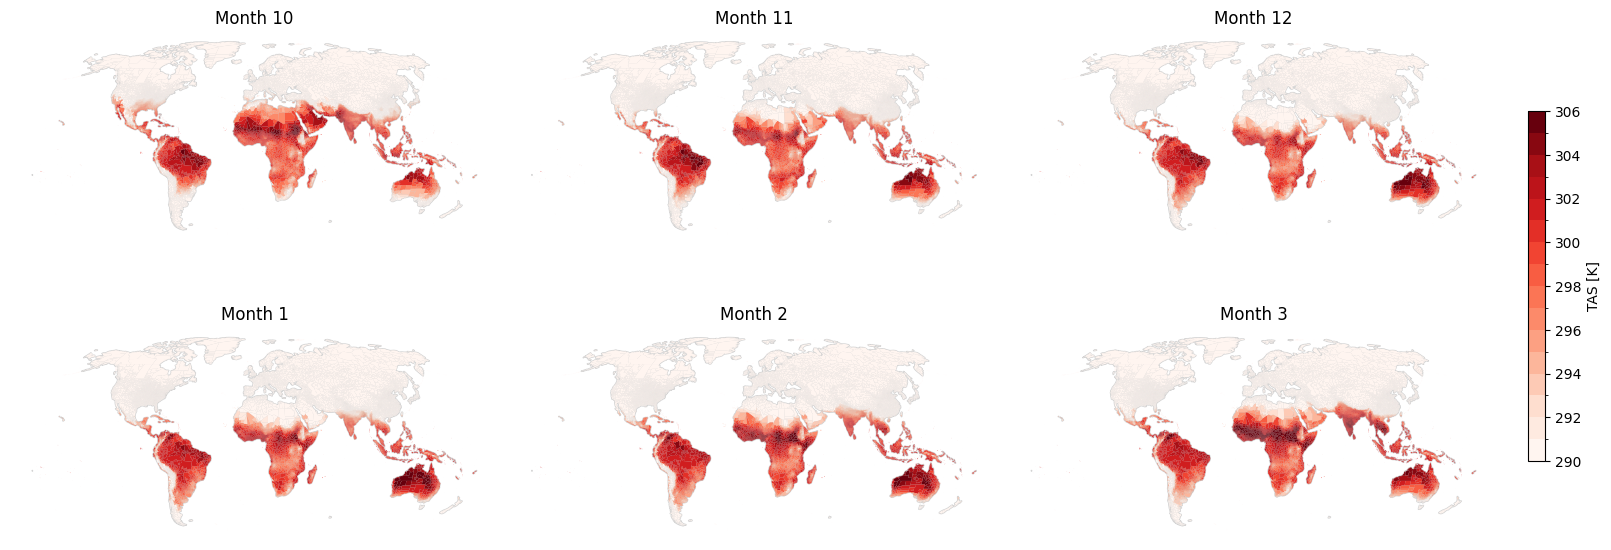

In [7]:
fig = plotting_utils.plot_monthly(
    _polygons_forecast,
    col="tas",
    vmin=290,
    vmax=306,
    n_colors = 15,
    cm="Reds",
    sup_title="",
    cbar_label="TAS [K]",
    month_order=config.months,
)

### Forecast Anomaly

In [8]:
forecast = xr.open_zarr("../data/v2610/v20261006_parsed_forecast.zarr")
hindcast = xr.open_zarr("../data/v2610/v20261006_parsed_hindcast.zarr")

anomaly = forecast.mean(dim="number").groupby('time.month').mean()-hindcast.groupby('time.month').mean()
# Gridded to Impact Region
anomaly_ir = isku_utils.grid_to_ir(anomaly, savefile=None)

_polygons_anomaly = analysis_utils.xarray_to_gpd(anomaly_ir["tas"], config.polygons)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


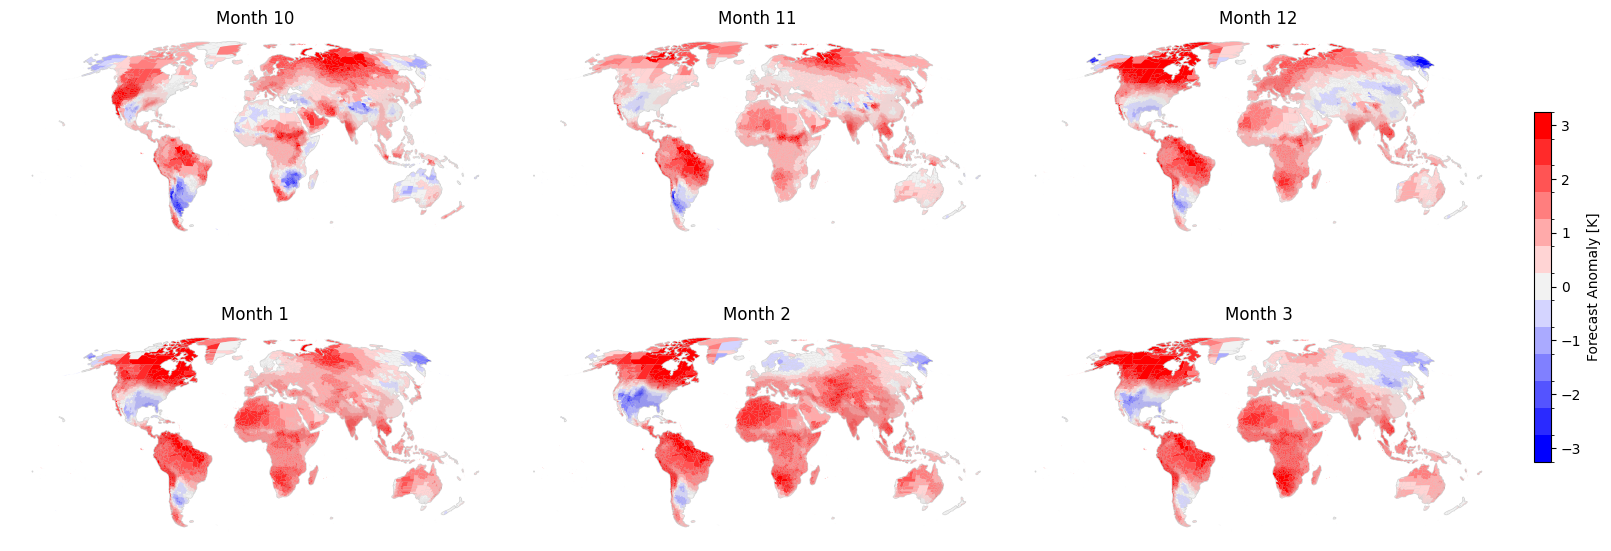

In [11]:
fig = plotting_utils.plot_monthly(
    _polygons_anomaly,
    col="tas",
    vmin=-3,
    vmax=3,
    n_colors = 13,
    cm="bwr",
    sup_title="",
    cbar_label="Forecast Anomaly [K]",
    month_order=config.months,
)

In [10]:
# Global Average Temp

### Impact

In [ ]:
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months)

In [ ]:
# Plot Impact on a Monthly Basis
_polygons_impact = analysis_utils.xarray_to_gpd(
    impact.mean(dim=["number", "sample"]), config.polygons
)
fig = plotting_utils.plot_monthly(
    _polygons_impact,
    col="age_weighted_impact",
    cm="bwr",
    n_colors=13,
    sup_title="",
    cbar_label=impact.units,
    month_order=[9, 10, 11, 12, 1, 2],
)

In [ ]:
# Aggregate Impact Regions to group_level
group_level = "ISO"  # IR: Impact region, # ADM1: State level, # ISO: Country level
# Use a subset of ensemble members for quick testing (.sel(number = ...))
impact, merge_key, base_cols = analysis_utils.aggregate_impact(
    impact, config, group_level
)